<a href="https://colab.research.google.com/github/MankotiaGit/Statistical-Foundation-of-Data-Sciences-/blob/main/FINAL_PRACTICAL_SFDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import the required libraries.

Step 2: Generate the dataset of 500 students.

Step 3: Display the dataset and class distribution.

Step 4: Fit Logistic Regression using Statsmodels.

Step 5: Display the model summary and odds ratios.

Step 6: Split the data into training and testing sets (70:30).

Step 7: Train the Logistic Regression model using Scikit-learn.

Step 8: Predict results and calculate accuracy.

Step 9: Display the confusion matrix.

Step 10: Plot the ROC curve and calculate AUC.

Step 11: Find the threshold for at least 85% recall for the fail class.

Step 12: Display the confusion matrix at the selected threshold.

Step 13: Predict the pass probability for a student with 5 study hours and 60% attendance.

Step 14: Interpret the odds ratios and compare the thresholds.

Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    recall_score
)

Generating the dataset

In [2]:
rng = np.random.default_rng(6)

n = 500

hours = rng.uniform(0, 20, n)

attendance = rng.uniform(40, 100, n)

lg = -7 + 0.25 * hours + 0.07 * attendance

passed = (
    rng.random(n) < 1 / (1 + np.exp(-lg))
).astype(int)

df = pd.DataFrame({
    'hours': hours,
    'attendance': attendance,
    'passed': passed
})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df['passed'].value_counts())

       hours  attendance  passed
0  10.763287   55.552356       0
1   6.865417   76.615560       1
2   7.381345   59.629027       0
3   7.489935   95.436536       0
4  19.748900   76.856084       1

Dataset shape: (500, 3)

Class distribution:
passed
1    277
0    223
Name: count, dtype: int64


1. Fit a logistic regression with statsmodels.api.Logit ; print the summary and the odds
ratios (exp of coefficients).


In [3]:
X = df[['hours', 'attendance']]
y = df['passed']

# Add intercept
X_sm = sm.add_constant(X)

# Fit logistic regression
model = sm.Logit(y, X_sm)

result = model.fit()

# Print summary
print(result.summary())

# Print odds ratios
odds_ratios = np.exp(result.params)

print("\nOdds Ratios:")
print(odds_ratios)

Optimization terminated successfully.
         Current function value: 0.429923
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 passed   No. Observations:                  500
Model:                          Logit   Df Residuals:                      497
Method:                           MLE   Df Model:                            2
Date:                Sat, 28 Nov 2026   Pseudo R-squ.:                  0.3745
Time:                        05:51:34   Log-Likelihood:                -214.96
converged:                       True   LL-Null:                       -343.65
Covariance Type:            nonrobust   LLR p-value:                 1.290e-56
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.8707      0.744    -10.586      0.000      -9.328      -6.413
hours          0.2672      0.

Fiting a Logistic Regression model using statsmodels and calculates the odds ratios to understand how study hours and attendance affect the probability of passing.

2. Split 70/30 with random_state=6 , refit with scikit-learn and report accuracy and the
confusion matrix at threshold 0.5.


In [4]:
X = df[['hours', 'attendance']]
y = df['passed']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=6
)

# Create model
lr = LogisticRegression()

# Train model
lr.fit(X_train, y_train)

# Predict probabilities
y_prob = lr.predict_proba(X_test)[:, 1]

# Predict using threshold 0.5
y_pred = (y_prob >= 0.5).astype(int)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

Accuracy: 0.8066666666666666

Confusion Matrix:
[[55 17]
 [12 66]]


Spliting the dataset, trains a Logistic Regression model using scikit-learn, predicts student results, and evaluates the model's performance.

3. Plot the ROC curve and report AUC.


AUC: 0.8990384615384616


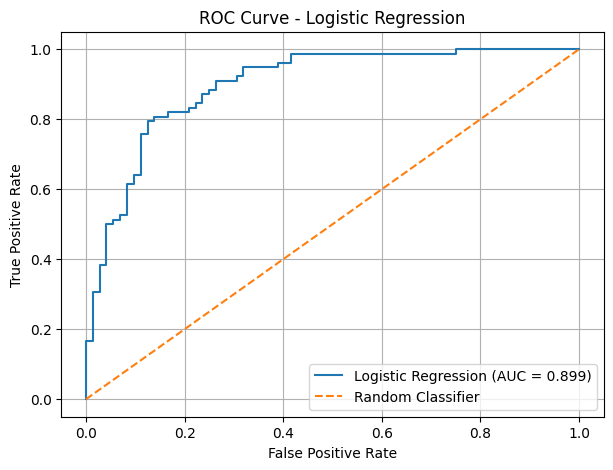

In [5]:
# Calculate ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc = roc_auc_score(y_test, y_prob)

print("AUC:", auc)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)

plt.show()

An AUC of approximately 0.899 indicates that the model has good ability to distinguish between students who pass and fail.

4. Find the threshold that gives at least 85% recall for the fail class and report the
confusion matrix at that threshold

In [6]:
# Probability of failure
fail_prob = 1 - y_prob

# Actual fail class
y_fail = (y_test == 0).astype(int)

# ROC for fail class
fpr_fail, tpr_fail, thresholds_fail = roc_curve(
    y_fail,
    fail_prob
)

# Find thresholds with recall >= 0.85
valid_indices = np.where(tpr_fail >= 0.85)[0]

# Select the first qualifying threshold
best_index = valid_indices[0]

threshold = thresholds_fail[best_index]

print("Chosen threshold:", threshold)
print("Recall for fail class:", tpr_fail[best_index])

Chosen threshold: 0.4246054865072426
Recall for fail class: 0.8611111111111112


The selected threshold is approximately 0.425.

In [7]:
# Predict fail if fail probability >= threshold
predicted_fail = (fail_prob >= threshold).astype(int)

# Convert predictions back to original labels
y_pred_threshold = np.where(predicted_fail == 1, 0, 1)

# Confusion matrix
cm_threshold = confusion_matrix(y_test, y_pred_threshold)

print("Confusion Matrix at chosen threshold:")
print(cm_threshold)

# Recall for fail class
fail_recall = recall_score(y_fail, predicted_fail)

print("\nRecall for fail class:", fail_recall)

Confusion Matrix at chosen threshold:
[[62 10]
 [15 63]]

Recall for fail class: 0.8611111111111112


This achieves approximately 86.11% recall, which satisfies the requirement of at least 85%.

5. Predict the pass probability for a student with 5 study hours and 60% attendance

In [8]:
student = pd.DataFrame({
    'const': [1],
    'hours': [5],
    'attendance': [60]
})

pass_probability = result.predict(student)

print("Pass Probability:", pass_probability.iloc[0])

Pass Probability: 0.14331232369446711


The predicted probability of passing is approximately 14.33%.

Therefore, according to the model, this student is at high risk of failing.